# Tabletop Game Simulation: Settlers of Catan

## My Question
What is the number of resources which the player can expect to collect in the next ten turns in the game of Catan? Assume that it is the beginning stage of the game. Initial placement is over, the robber has not placed himself yet on any of the player’s hexes, and no one else is preventing him/her. The pieces of the player are located on the following hexes:

| Piece | Hex number | Cards per matching roll |
|---|---|---|
| **City** | 6 | 2 |
| Settlement | 8 | 1 |
| Settlement | 5 | 1 |
| Settlement | 9 | 1 |



## Type of Study
This is an example of a computer simulation. Rather than conducting surveys or experimental studies on the actual population for obtaining information, or conducting an experiment, I use a computer to simulate the random process of rolling dice in Catan repeatedly. The ratio of how often each event occurs approximates the probability of that event occurring. In this case, the random variable is discrete.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=2026)

In [ ]:
def cards_for_roll(roll):
    """How many cards does the player get for one dice sum?"""
    if roll == 6:
        return 2          
    elif roll in (5, 8, 9):
        return 1          
    else:
        return 0          

def one_trial(turns=10):
    """One trial = 10 turns. Returns X, the total cards collected."""
    total = 0
    for _ in range(turns):
        roll = rng.integers(1, 7) + rng.integers(1, 7)   
        total += cards_for_roll(roll)
    return total

n_trials = 1000
X = np.array([one_trial() for _ in range(n_trials)])

print("First 20 simulated values of X:", X[:20])
print("Smallest X:", X.min(), "  Largest X:", X.max())

First 20 simulated values of X: [ 4  7 10  6  9 12  4  0  5  7  6  6  3  4  3  4  6  4  9  8]
Smallest X: 0   Largest X: 14


In [ ]:
counts = pd.Series(X).value_counts().sort_index()

dist = pd.DataFrame({'x (cards)': counts.index, 'trials': counts.values})
dist['P(X = x)'] = dist['trials'] / n_trials
dist['P(X ≤ x)'] = dist['P(X = x)'].cumsum()

print("Sum of probabilities:", round(dist['P(X = x)'].sum(), 4))
dist.round(3)

Sum of probabilities: 1.0


,x (cards),trials,P(X = x),P(X ≤ x)
0,0,1,0.001,0.001
1,1,5,0.005,0.006
2,2,23,0.023,0.029
3,3,63,0.063,0.092
4,4,117,0.117,0.209
5,5,171,0.171,0.380
6,6,181,0.181,0.561
7,7,165,0.165,0.726
8,8,119,0.119,0.845
9,9,78,0.078,0.923


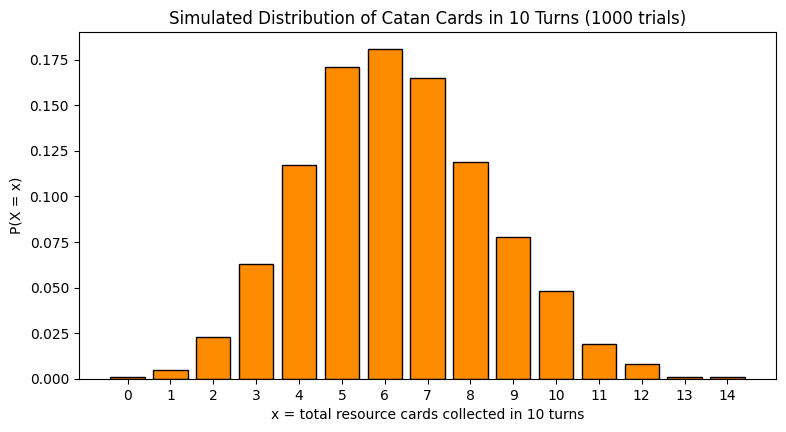

In [ ]:
plt.figure(figsize=(9, 4.5))
plt.bar(dist['x (cards)'], dist['P(X = x)'], color='darkorange', edgecolor='black')
plt.xlabel('x = total resource cards collected in 10 turns')
plt.ylabel('P(X = x)')
plt.title('Simulated Distribution of Catan Cards in 10 Turns (1000 trials)')
plt.xticks(range(0, int(dist['x (cards)'].max()) + 1))
plt.show()

In [ ]:
dist['x · P(x)'] = dist['x (cards)'] * dist['P(X = x)']
mu = dist['x · P(x)'].sum()

dist['(x − μ)² · P(x)'] = (dist['x (cards)'] - mu) ** 2 * dist['P(X = x)']
variance = dist['(x − μ)² · P(x)'].sum()
sigma = np.sqrt(variance)

display(dist[['x (cards)', 'P(X = x)', 'x · P(x)', '(x − μ)² · P(x)']].round(4))
print(f"Expected value:     μ_X = {mu:.2f} cards")
print(f"Variance:           σ²_X = {variance:.2f}")
print(f"Standard deviation: σ_X = {sigma:.2f} cards")

,x (cards),P(X = x),x · P(x),(x − μ)² · P(x)
0,0,0.001,0.000,0.0393
1,1,0.005,0.005,0.1389
2,2,0.023,0.046,0.4194
3,3,0.063,0.189,0.6737
4,4,0.117,0.468,0.6029
5,5,0.171,0.855,0.2758
6,6,0.181,1.086,0.0132
7,7,0.165,1.155,0.0879
8,8,0.119,0.952,0.3562
9,9,0.078,0.702,0.5813


Expected value:     μ_X = 6.27 cards
Variance:           σ²_X = 4.65
Standard deviation: σ_X = 2.16 cards


In [ ]:
ways = {2:1, 3:2, 4:3, 5:4, 6:5, 7:6, 8:5, 9:4, 10:3, 11:2, 12:1}

p_turn = np.array([
    sum(w for s, w in ways.items() if cards_for_roll(s) == 0),
    sum(w for s, w in ways.items() if cards_for_roll(s) == 1),
    sum(w for s, w in ways.items() if cards_for_roll(s) == 2),
]) / 36

exact = np.array([1.0])
for _ in range(10):
    exact = np.convolve(exact, p_turn)

xs = np.arange(len(exact))
mu_exact = (xs * exact).sum()
sigma_exact = np.sqrt(((xs - mu_exact) ** 2 * exact).sum())

print(f"Per-turn probabilities: P(0)={p_turn[0]:.3f}, P(1)={p_turn[1]:.3f}, P(2)={p_turn[2]:.3f}")
print(f"Simulated: μ = {mu:.2f}, σ = {sigma:.2f}")
print(f"Exact:     μ = {mu_exact:.2f}, σ = {sigma_exact:.2f}")

Per-turn probabilities: P(0)=0.500, P(1)=0.361, P(2)=0.139
Simulated: μ = 6.27, σ = 2.16
Exact:     μ = 6.39, σ = 2.25


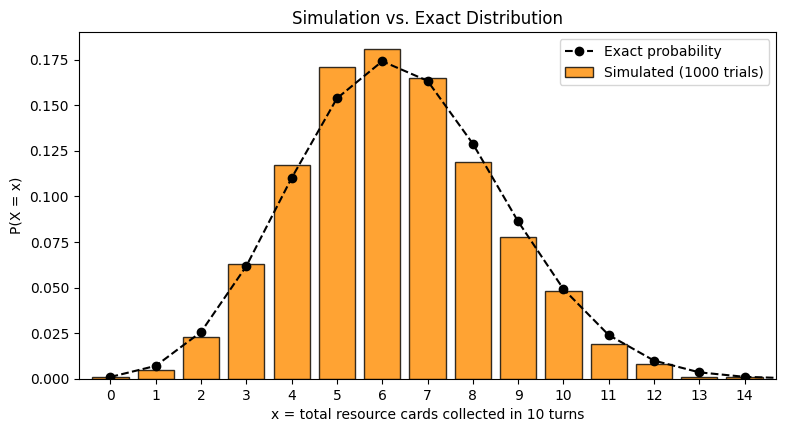

In [ ]:
plt.figure(figsize=(9, 4.5))
plt.bar(dist['x (cards)'], dist['P(X = x)'], color='darkorange', edgecolor='black',
        alpha=0.8, label='Simulated (1000 trials)')
plt.plot(xs, exact, 'ko--', label='Exact probability')
plt.xlabel('x = total resource cards collected in 10 turns')
plt.ylabel('P(X = x)')
plt.title('Simulation vs. Exact Distribution')
plt.xticks(range(0, 15))
plt.xlim(-0.7, 14.7)
plt.legend()
plt.show()

## My Conclusion
In the next 10 moves, the player can expect to get approximately 6.27 resource cards on average (μ ≈ 6.27 cards). The standard deviation is around 2.16 cards, which means that in any given period of 10 moves, the player’s total number of cards will differ from 6.27 by around 2 cards, so a usual period of 10 moves will contain somewhere from 4 to 8 cards. According to the simulation results, in 91% of cases, the player gets 4 or more cards, while in 9% – 3 or fewer. In just 15.5% of cases, the player got 9 or more cards.

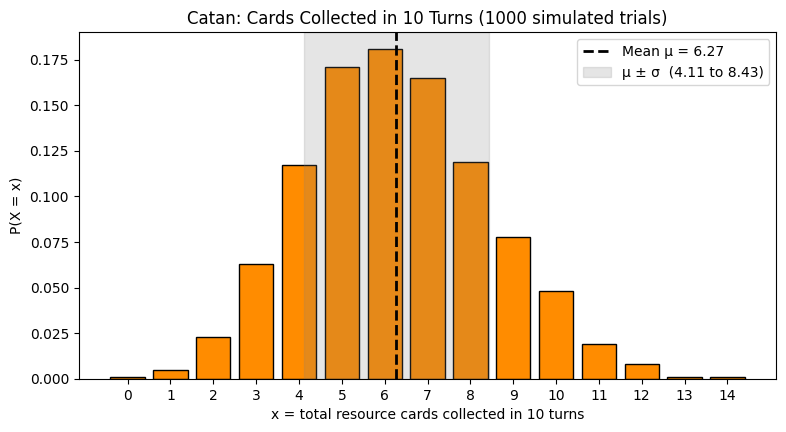

In [8]:
plt.figure(figsize=(9, 4.5))
plt.bar(dist['x (cards)'], dist['P(X = x)'], color='darkorange', edgecolor='black')
plt.axvline(mu, color='black', linestyle='--', linewidth=2, label=f'Mean μ = {mu:.2f}')
plt.axvspan(mu - sigma, mu + sigma, color='gray', alpha=0.2, label=f'μ ± σ  ({mu - sigma:.2f} to {mu + sigma:.2f})')
plt.xlabel('x = total resource cards collected in 10 turns')
plt.ylabel('P(X = x)')
plt.title('Catan: Cards Collected in 10 Turns (1000 simulated trials)')
plt.xticks(range(0, int(dist['x (cards)'].max()) + 1))
plt.legend()
plt.show()

3. Explanation of the graph: The histogram appears to be roughly symmetric and unimodal; it looks skewed to the right slightly since it has a clear peak near 6 cards and a long tail in the higher values range (10-14 cards). The dashed line indicates the mean value of 6.27 cards, and it is located right in the middle of the highest bars, which means that approximately 6 cards is the long-run average. The shaded area represents one standard deviation above and below the mean value (approximately 4.1 to 8.4 cards); all of the bars' height is inside of it, and it agrees with the statement that a typical 10-turn total is within about 2 cards of the mean. The height of the bars drops significantly above 10 cards and 0 to 2 cards, which implies that extremely lucky or unlucky stretches are rare, but still occur. For the confirmation, the exact calculations of the mean and standard deviation were done according to the laws of probability, and the obtained results agree with the simulation bars.